# 06 · Optimización con seguimiento · Buscar mejor, y comprobar que es real

> **BORRADOR para revisión del grupo.** La búsqueda ve solo el 75 % del entrenamiento; el 25 % restante se **reserva** para comprobar lo encontrado. La prueba cerrada **no se abre**.
> Cada ensayo queda registrado en **MLflow** (local). Lo marcado **[DECIDE EL GRUPO]** necesita una decisión de negocio, con una propuesta razonada.
> El código vive en `src/proyecto/models/tuning.py` (espacios de búsqueda, pipeline con parámetros, intervalo) con pruebas en `tests/test_tuning.py`; este notebook solo lo orquesta.

## Resumen para quien decide

| | Lo que se midió | Qué significa para el negocio |
|---|---|---|
| **1** | Se optimizaron los **dos finalistas** con **20 ensayos cada uno** (presupuesto fijado antes) | Se probaron 40 configuraciones; todas quedaron registradas y se pueden auditar |
| **2** | **LightGBM:** la búsqueda "encontró" una mejora (costo 0,3270 → 0,3259), pero **en los datos reservados desaparece**: diferencia **+0,0003**, intervalo del 95 % **[-0,0017, +0,0023]**, que cruza el cero | Es el **sesgo optimista**: entre 20 intentos con ruido, el mejor siempre parece mejor de lo que es. **Se conservan los parámetros de partida** |
| **3** | **Regresión logística:** el mejor ensayo de los 20 fue **la propia configuración de partida** | No había nada que mejorar |
| **4** | **Umbral:** el teórico (16,7 %) casi coincide con el óptimo empírico (16,0 %); entre 15 % y 17,5 % el costo varía menos de 0,001 | El umbral **1 ÷ (R + 1)** funciona: **no hace falta afinarlo**, y es robusto a pequeños errores en R |
| **5** | **Capacidad:** contactar al ≈ 35 % mejor puntuado equivale al umbral; llamar solo al 20 % sube el costo a 0,387 | Limitar las llamadas al 20 % cuesta **≈ 6.000 unidades por 100.000 clientes** |
| **6** | **LightGBM contra regresión en los datos reservados:** la regresión cuesta +0,0025 más, intervalo **[-0,0006, +0,0052]**, que cruza el cero | **No se distinguen con certeza**: el modelo explicable cuesta ≈ 250 unidades por 100.000 clientes, y esa diferencia **no es demostrable** |

**Conclusión de la etapa:** los parámetros del torneo **ya eran buenos**. Optimizar dio cero mejora demostrable, y **eso es un resultado válido**. El valor está en lo que se comprobó: el umbral, la capacidad y la cercanía de los dos finalistas.

## 0. Cargar el entrenamiento y reservar clientes que la búsqueda nunca verá

**Un cliente por fila** (`id` único), así que reservar por fila es reservar por cliente: ningún cliente puede estar de los dos lados. Se separa un **25 % estratificado por `Response`** (semilla 7). La búsqueda trabaja solo con el 75 %; para valorar cada ensayo usa **3 pliegues** dentro de ese 75 % (más rápido que los 5 del torneo).

In [1]:
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import optuna

from proyecto.data import split as sp
from proyecto.data.loading import load_train
from proyecto.models.metrics import cost_per_client, decision_threshold, technical_metrics
from proyecto.models.tuning import FINALISTS, START_PARAMS, bootstrap_interval, build_tuned_pipeline, per_client_cost, run_search
from proyecto.tracking.mlflow_utils import configure_mlflow, set_experiment, log_run

optuna.logging.set_verbosity(optuna.logging.WARNING)
TARGET = "Response"
BLUE, ORANGE, GRAY, LIGHT, INK = "#2F6FB5", "#D9822B", "#8A8A8A", "#C9C9C4", "#222222"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#cccccc",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#eeeeee",
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left", "figure.dpi": 110})
LABELS = {"lightgbm": "LightGBM", "regresion_logistica": "Regresión logística"}

train = load_train(ROOT)                        # solo entrenamiento: la prueba cerrada no se carga
search, reserved = sp.split_train_holdout(train, test_size=0.25, seed=7)      # 75 % busca, 25 % comprueba
Xs, ys = search.drop(columns=[TARGET]), search[TARGET].to_numpy()
Xr, yr = reserved.drop(columns=[TARGET]), reserved[TARGET].to_numpy()
search_folds = sp.stratified_folds(search, n_splits=3)

assert set(search["id"]).isdisjoint(set(reserved["id"])), "hay clientes en los dos lados"
print(f"Búsqueda: {len(search):,} clientes (tasa {ys.mean():.3%}). Reservados: {len(reserved):,} clientes (tasa {yr.mean():.3%}).")
print(f"La búsqueda valora cada ensayo con {len(search_folds)} pliegues estratificados dentro del 75 %.")

2026/10/31 11:25:57 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at <repo>\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Búsqueda: 228,665 clientes (tasa 12.256%). Reservados: 76,222 clientes (tasa 12.256%).
La búsqueda valora cada ensayo con 3 pliegues estratificados dentro del 75 %.


## 1. La regla de decisión, escrita antes de mirar

**Regla propuesta [DECIDE EL GRUPO: confirmar]:**

> **Uso los parámetros optimizados solo si TODO el intervalo del 95 % de la diferencia de costo está por debajo de cero** (en los clientes reservados). Si el intervalo cruza el cero, la mejora no se distingue del ruido y **uso los de partida**.

**Por qué esta regla:** la mejor puntuación de una búsqueda es **optimista**. Es el máximo de muchas estimaciones con ruido: si se prueban 20 configuraciones parecidas, una saldrá "mejor" por azar. Comprobarla en clientes que la búsqueda no vio elimina ese sesgo.
También tiene una razón de negocio: **cambiar un modelo cuesta** (reentrenar, revalidar, volver a documentar). Solo se cambia si la mejora es real.

**Reglas complementarias (también escritas antes):**
- **Umbral:** se mantiene el teórico `1 ÷ (R + 1)` salvo que un umbral distinto sea mejor **con intervalo completo por debajo de cero** en los reservados.
- **Qué finalista pasa a la validación final:** el de menor costo en los reservados **si su intervalo contra el otro queda por debajo de cero**; si cruza el cero, es un empate y decide la **explicabilidad** (decisión 1 del notebook 05 **[DECIDE EL GRUPO]**).

## 2. Espacio de búsqueda y presupuesto

El **espacio de búsqueda es conocimiento, no azar**: cada rango acota un parámetro con lo que se sabe del algoritmo. Un espacio plausible pero equivocado puede dar un resultado peor que no optimizar. **Todos los rangos incluyen el valor de partida** (se comprueba con una prueba automática), para que la búsqueda pueda "elegir quedarse donde estaba".

**Presupuesto fijado antes:** **20 ensayos por finalista**. Cada ensayo cuesta tiempo (3 ajustes). Con tan pocos ensayos, una búsqueda inteligente (Optuna, algoritmo TPE) y una aleatoria suelen llegar al mismo lugar. **El ensayo 0 es siempre la configuración de partida**, medida con los mismos pliegues: así la comparación es limpia.

| Finalista | Parámetro | Rango | Valor de partida | Qué controla y por qué ese rango |
|---|---|---|---|---|
| **LightGBM** | `n_estimators` | 100 a 500 | 200 | Cuántos árboles: pocos subajustan, muchos sobreajustan |
| | `learning_rate` | 0,02 a 0,2 (escala log) | 0,08 | Cuánto corrige cada árbol; con tasa baja hacen falta más árboles |
| | `num_leaves` | 8 a 64 | 31 | Complejidad de cada árbol |
| | `min_child_samples` | 20 a 400 (escala log) | 100 | Mínimo de clientes por hoja: evita hojas con 5 clientes |
| | `subsample` | 0,6 a 1,0 | 0,8 | Fracción de clientes que ve cada árbol |
| | `colsample_bytree` | 0,5 a 1,0 | 0,8 | Fracción de columnas que ve cada árbol |
| | `reg_lambda` | 0 a 10 | 0 | Penaliza pesos grandes (regularización) |
| **Regresión logística** | `C` | 0,001 a 10 (escala log) | 1 | Inverso de la regularización: más pequeño, más suave |
| | `age_spline_knots` | 4 a 12 | 6 | Flexibilidad de la curva de la edad |
| | `profile_12` | sí / no | no | Añadir los 12 perfiles (la idea que quedó "en observación" en la etapa 4) |

## 3. Conexión con el seguimiento (MLflow local)

En esta etapa el seguimiento es **local**: todo queda en `mlflow_local.db` (raíz del repo, ignorado por Git). **Databricks entra en la etapa 8.** Cada ensayo es **una ejecución registrada** con sus parámetros, sus métricas y etiquetas.
Para verlo en el navegador: `mlflow ui --backend-store-uri sqlite:///mlflow_local.db`.

In [2]:
with warnings.catch_warnings(record=True) as notices:
    warnings.simplefilter("always")
    tracking_where = configure_mlflow(force_local=True)       # seguimiento local
for notice in notices:
    print("Aviso:", notice.message)
EXPERIMENT = set_experiment("venta-cruzada-seguros-optimizacion")
EXEC_ID = time.strftime("%Y%m%d-%H%M%S")                       # identifica ESTA ejecución del notebook
print("MLflow:", tracking_where, "| experimento:", EXPERIMENT, "| ejecución:", EXEC_ID)

MLflow: local | experimento: venta-cruzada-seguros-optimizacion | ejecución: 20261031-112601


## 4. La búsqueda: un ensayo = una ejecución registrada

La métrica de la búsqueda es **la misma del torneo**: el **costo por cliente** (R = 5, umbral 16,7 %), promediado en 3 pliegues. Se registran también PR-AUC y log loss como control.
Son unos 6 minutos: LightGBM es el más lento.

In [3]:
N_TRIALS = 20            # presupuesto fijado antes de empezar
studies, trial_tables = {}, {}
t_start = time.time()

for finalist in FINALISTS:
    def register(study, trial, finalist=finalist):
        # Un ensayo = una ejecución registrada: parámetros, métricas y etiquetas
        log_run(run_name=f"{finalist}-ensayo-{trial.number:02d}", params=trial.params,
                metrics={"cost": trial.value, "cost_sd": trial.user_attrs["cost_sd"], "pr_auc": trial.user_attrs["pr_auc"], "log_loss": trial.user_attrs["log_loss"]},
                tags={"etapa": "06_optimizacion", "finalista": finalist, "ejecucion": EXEC_ID, "es_partida": str(trial.number == 0)})

    # La búsqueda vive en src/proyecto/models/tuning.py: el ensayo 0 es siempre la configuración de partida
    study = run_search(finalist, Xs, ys, search_folds, n_trials=N_TRIALS, seed=42, on_trial=register)
    studies[finalist] = study
    trial_tables[finalist] = pd.DataFrame([{"ensayo": t.number, "costo": t.value, "± entre pliegues": t.user_attrs["cost_sd"], "PR-AUC": t.user_attrs["pr_auc"],
                                            "log loss": t.user_attrs["log_loss"], **t.params} for t in study.trials]).set_index("ensayo")
print(f"{sum(len(s.trials) for s in studies.values())} ensayos en {(time.time() - t_start) / 60:.1f} minutos.")

summary = pd.DataFrame({
    LABELS[f]: {"costo de partida (ensayo 0)": s.trials[0].value, "mejor costo encontrado": s.best_value, "mejora aparente": s.trials[0].value - s.best_value,
                "mejor ensayo": s.best_trial.number, "puesto de la partida (de 20)": int(sorted(t.value for t in s.trials).index(s.trials[0].value) + 1),
                "peor ensayo": max(t.value for t in s.trials)}
    for f, s in studies.items()
}).T
display(summary.style.format({"costo de partida (ensayo 0)": "{:.4f}", "mejor costo encontrado": "{:.4f}", "mejora aparente": "{:+.4f}", "peor ensayo": "{:.4f}",
                              "mejor ensayo": "{:.0f}", "puesto de la partida (de 20)": "{:.0f}"}))

40 ensayos en 5.6 minutos.


,costo de partida (ensayo 0),mejor costo encontrado,mejora aparente,mejor ensayo,puesto de la partida (de 20),peor ensayo
LightGBM,0.3270,0.3259,+0.0011,13,11,0.3326
Regresión logística,0.3277,0.3277,+0.0000,0,1,0.3344


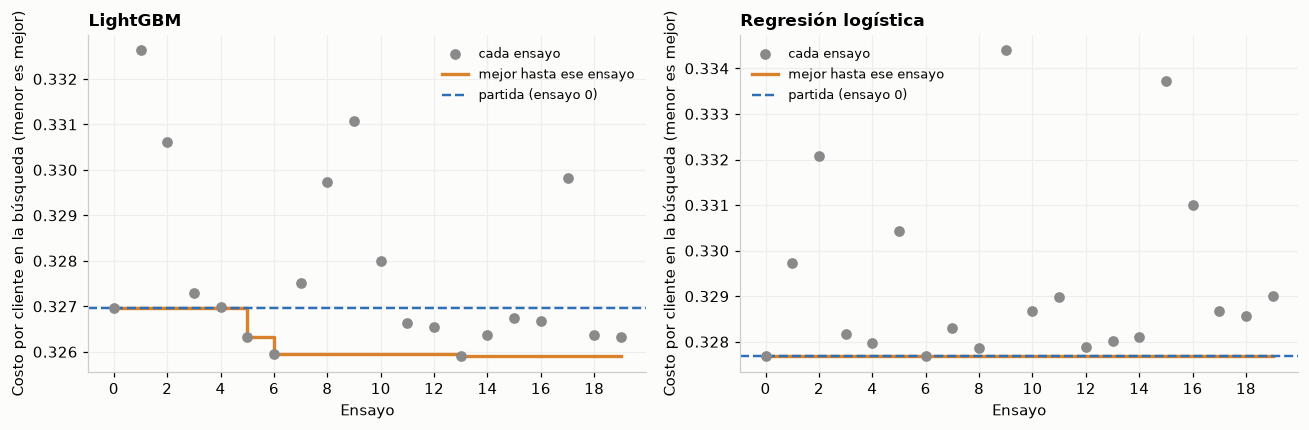

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, finalist in zip(axes, FINALISTS):
    table = trial_tables[finalist]
    best_so_far = table["costo"].cummin()
    ax.scatter(table.index, table["costo"], color=GRAY, s=36, zorder=3, label="cada ensayo")
    ax.step(table.index, best_so_far, where="post", color=ORANGE, lw=2.2, label="mejor hasta ese ensayo")
    ax.axhline(table["costo"].iloc[0], color=BLUE, ls="--", lw=1.6, label="partida (ensayo 0)")
    ax.set_xlabel("Ensayo")
    ax.set_ylabel("Costo por cliente en la búsqueda (menor es mejor)")
    ax.set_title(LABELS[finalist])
    ax.set_xticks(range(0, N_TRIALS, 2))
    ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

### 4.1 Lectura de la búsqueda

- **LightGBM:** el costo de la partida es **0,3270**; la búsqueda encontró **0,3259** en el ensayo 13 (**mejora aparente de 0,0011**). Los 20 ensayos van de 0,3259 a 0,3326: **la partida está en el puesto 11 de 20**, en la mitad del rango. Hay una **zona plana**: la mayoría de las configuraciones razonables rinde casi igual, y solo las extremas empeoran.
- **Regresión logística:** **ninguno de los 19 ensayos superó a la partida** (puesto 1 de 20); el ensayo 6 la igualó en costo (0,3277), con una PR-AUC algo mayor (0,359 frente a 0,358), una diferencia dentro del ruido. El mejor valor es el del ensayo 0: `C = 1`, 6 puntos de quiebre y sin los 12 perfiles. Los demás van de 0,3277 a 0,3344.
- **El ruido entre pliegues dentro de la búsqueda es de ≈ 0,0006**, y la mejora aparente de LightGBM es de 0,0011: **parece casi 2 veces el ruido**. Pero ese ruido **subestima** el real: elegir el mejor de 20 intentos produce una mejora aparente aunque no haya ninguna real. La comprobación de la sección 6 lo resuelve.

## 5. ¿Qué parámetros importaron?

Optuna estima qué parte de la variación del costo explica cada parámetro. Es útil para **saber dónde mirar la próxima vez**.

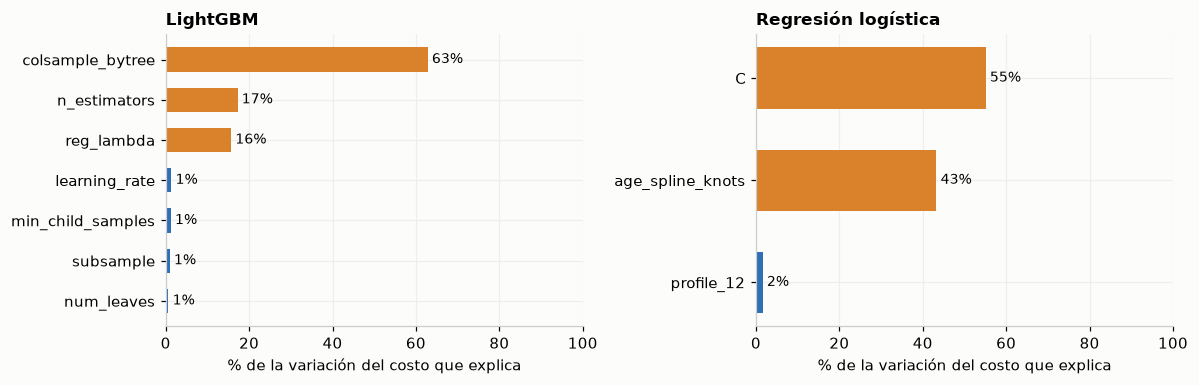

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, finalist in zip(axes, FINALISTS):
    importance = pd.Series(optuna.importance.get_param_importances(studies[finalist])).sort_values()
    ax.barh(importance.index, importance.to_numpy() * 100, color=[ORANGE if v > 0.15 else BLUE for v in importance], height=0.6)
    for i, v in enumerate(importance):
        ax.text(v * 100 + 1, i, f"{v:.0%}", va="center", fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_xlabel("% de la variación del costo que explica")
    ax.set_title(LABELS[finalist])
plt.tight_layout()
plt.show()

**Lectura:**
- **LightGBM:** `colsample_bytree` (la fracción de columnas que ve cada árbol) explica ≈ **63 %** de la variación; luego `n_estimators` (≈ 17 %) y `reg_lambda` (≈ 16 %). Los demás casi no importan (≈ 1 % cada uno). Es decir, **el modelo es poco sensible a casi todo**: señal de que ya estaba en una zona estable.
- **Regresión:** pesan `C` (≈ 55 %) y la flexibilidad de la edad `age_spline_knots` (≈ 43 %). Añadir los 12 perfiles casi no cuenta (≈ 2 %), lo que **confirma la decisión de la etapa 4 de no incluirlos**.
- **Para la próxima vez:** si hubiera que volver a optimizar LightGBM, valdría la pena **acotar el espacio** a `colsample_bytree` y `n_estimators` y fijar el resto.

## 6. La comprobación honesta: en clientes que la búsqueda no vio

Se entrenan **dos modelos por finalista** con el 75 % (parámetros de **partida** y **optimizados**) y se comparan en el 25 % reservado. La diferencia se calcula **cliente por cliente** (costo del optimizado menos costo de la partida) y su **intervalo del 95 %** remuestrea **clientes completos**. Negativo = el optimizado mejora.

,costo con parámetros de partida,costo con parámetros optimizados,diferencia (optimizado - partida),intervalo 95 % (bajo),intervalo 95 % (alto),¿todo el intervalo bajo cero?,parámetros que se usarán
LightGBM,0.3241,0.3244,+0.0003,-0.0017,+0.0023,no,de partida
Regresión logística,0.3266,0.3266,+0.0000,+0.0000,+0.0000,no,de partida


,PR-AUC partida,PR-AUC optimizado,log loss partida,log loss optimizado,Brier partida,Brier optimizado
LightGBM,0.3687,0.3694,0.2648,0.2648,0.0867,0.0866
Regresión logística,0.3538,0.3538,0.2667,0.2667,0.0873,0.0873


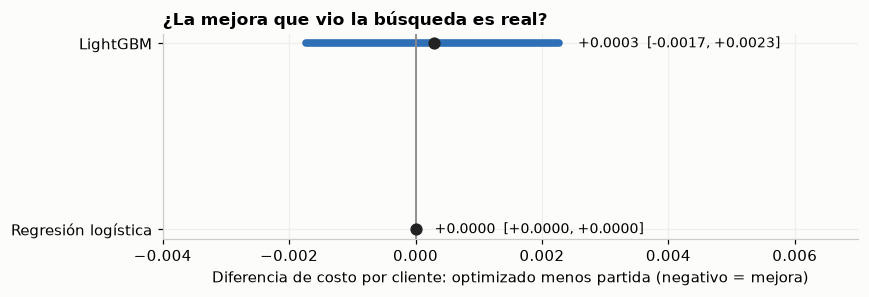

In [6]:
check = {}
for finalist in FINALISTS:
    best_params = studies[finalist].best_trial.params
    start_model = build_tuned_pipeline(finalist, START_PARAMS[finalist]).fit(Xs, ys)
    best_model = build_tuned_pipeline(finalist, best_params).fit(Xs, ys)
    p_start, p_best = start_model.predict_proba(Xr)[:, 1], best_model.predict_proba(Xr)[:, 1]
    difference = per_client_cost(yr, p_best) - per_client_cost(yr, p_start)
    low, high = bootstrap_interval(difference, reserved["id"].to_numpy())
    m_start, m_best = technical_metrics(yr, p_start), technical_metrics(yr, p_best)
    decision = "optimizados" if high < 0 else "de partida"
    check[finalist] = {"p_start": p_start, "p_best": p_best, "difference": difference, "low": low, "high": high,
                       "m_start": m_start, "m_best": m_best, "best_params": best_params, "decision": decision}

report = pd.DataFrame({
    LABELS[f]: {"costo con parámetros de partida": c["m_start"]["cost"], "costo con parámetros optimizados": c["m_best"]["cost"],
                "diferencia (optimizado - partida)": c["difference"].mean(), "intervalo 95 % (bajo)": c["low"], "intervalo 95 % (alto)": c["high"],
                "¿todo el intervalo bajo cero?": "sí" if c["high"] < 0 else "no", "parámetros que se usarán": c["decision"]}
    for f, c in check.items()
}).T
display(report.style.format({"costo con parámetros de partida": "{:.4f}", "costo con parámetros optimizados": "{:.4f}", "diferencia (optimizado - partida)": "{:+.4f}",
                             "intervalo 95 % (bajo)": "{:+.4f}", "intervalo 95 % (alto)": "{:+.4f}"}))

extra = pd.DataFrame({LABELS[f]: {"PR-AUC partida": c["m_start"]["pr_auc"], "PR-AUC optimizado": c["m_best"]["pr_auc"],
                                  "log loss partida": c["m_start"]["log_loss"], "log loss optimizado": c["m_best"]["log_loss"],
                                  "Brier partida": c["m_start"]["brier"], "Brier optimizado": c["m_best"]["brier"]} for f, c in check.items()}).T
display(extra.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(8, 2.8))
for i, finalist in enumerate(FINALISTS):
    c = check[finalist]
    ax.plot([c["low"], c["high"]], [i, i], color=ORANGE if c["high"] < 0 else BLUE, lw=5, solid_capstyle="round")
    ax.plot(c["difference"].mean(), i, "o", color=INK, ms=7, zorder=3)
    ax.text(c["high"] + 0.0003, i, f"{c['difference'].mean():+.4f}  [{c['low']:+.4f}, {c['high']:+.4f}]", va="center", fontsize=9)
ax.axvline(0, color=GRAY, lw=1.2)
ax.set_yticks(range(len(FINALISTS)))
ax.set_yticklabels([LABELS[f] for f in FINALISTS])
ax.set_xlim(-0.004, 0.007)
ax.invert_yaxis()
ax.set_xlabel("Diferencia de costo por cliente: optimizado menos partida (negativo = mejora)")
ax.set_title("¿La mejora que vio la búsqueda es real?")
plt.tight_layout()
plt.show()

**Resultado de la regla:**
- **LightGBM: el intervalo cruza el cero** (**[-0,0017, +0,0023]**) y la diferencia puntual es incluso **ligeramente positiva (+0,0003)**: la configuración "optimizada" **no es mejor**. La mejora aparente de 0,0011 de la búsqueda **era ruido**. **Se usan los parámetros de partida.**
- **Regresión logística:** la mejor configuración **era la de partida**, así que los dos modelos son idénticos: diferencia exactamente cero. **Se usan los de partida.**
- Las métricas de control **tampoco cambian**: PR-AUC 0,3687 → 0,3694 y log loss 0,2648 → 0,2648 en LightGBM; sin cambio en la regresión.

**Qué enseña esto al negocio:** si se hubiera reportado el mejor valor de la búsqueda (0,3259), se habría **prometido una mejora que no existe**. Comprobar en clientes reservados evitó una expectativa falsa, y evitó **cambiar un modelo ya validado por una versión que no es mejor** (con el costo de reentrenar, revalidar y documentar).

## 7. El umbral y la capacidad: ¿a cuántos llamar?

Aquí sí hay una decisión de negocio que mover. La regla de llamar a quien tenga probabilidad **superior a 1 ÷ (R + 1) = 16,7 %** es óptima **si las probabilidades son fieles**. Se comprueba con las **predicciones fuera de muestra de la búsqueda** (cada cliente predicho por un modelo que no lo vio), y después se confirma en los reservados.

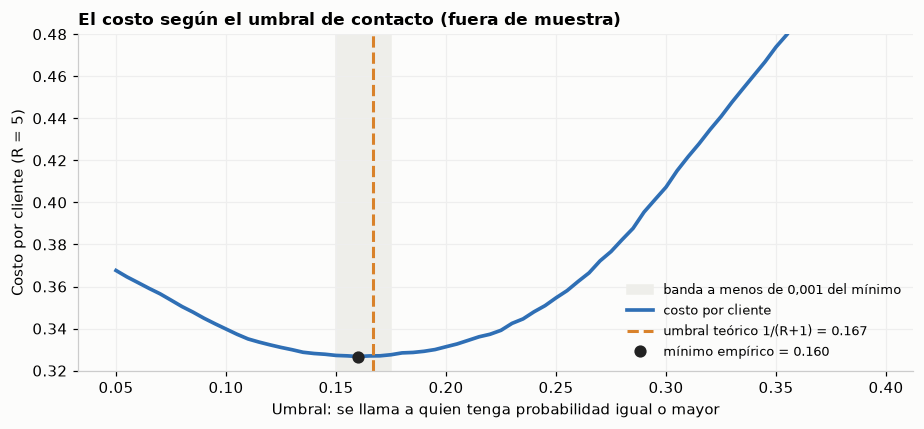

Costo con el umbral teórico (0.167): 0.3270 | mínimo empírico (0.160): 0.3267 | banda a menos de 0,001: 0.150 a 0.175


En los reservados: umbral 0.160 frente a 0.167: diferencia +0.0002, intervalo 95 % [-0.0011, +0.0015].


In [7]:
from sklearn.base import clone

def out_of_fold(finalist, params):
    proba = np.zeros(len(ys))
    for train_idx, valid_idx in search_folds:
        model = clone(build_tuned_pipeline(finalist, params)).fit(Xs.iloc[train_idx], ys[train_idx])
        proba[valid_idx] = model.predict_proba(Xs.iloc[valid_idx])[:, 1]
    return proba

oof_lgbm = out_of_fold("lightgbm", START_PARAMS["lightgbm"])      # con los parámetros que se usarán (los de partida)

thresholds = np.round(np.arange(0.05, 0.40, 0.005), 3)
cost_curve = np.array([cost_per_client(ys, (oof_lgbm >= t).astype(int)) for t in thresholds])
theory = decision_threshold()
empirical = float(thresholds[int(np.argmin(cost_curve))])
band = thresholds[cost_curve <= cost_curve.min() + 0.001]

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.axvspan(band.min(), band.max(), color="#eeeeea", zorder=0, label="banda a menos de 0,001 del mínimo")
ax.plot(thresholds, cost_curve, color=BLUE, lw=2.4, label="costo por cliente")
ax.axvline(theory, color=ORANGE, lw=2, ls="--", label=f"umbral teórico 1/(R+1) = {theory:.3f}")
ax.plot(empirical, cost_curve.min(), "o", color=INK, ms=7, zorder=4, label=f"mínimo empírico = {empirical:.3f}")
ax.set_xlabel("Umbral: se llama a quien tenga probabilidad igual o mayor")
ax.set_ylabel("Costo por cliente (R = 5)")
ax.set_title("El costo según el umbral de contacto (fuera de muestra)")
ax.set_ylim(0.32, 0.48)
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

cost_theory = cost_per_client(ys, (oof_lgbm >= theory).astype(int))
print(f"Costo con el umbral teórico ({theory:.3f}): {cost_theory:.4f} | mínimo empírico ({empirical:.3f}): {cost_curve.min():.4f} | banda a menos de 0,001: {band.min():.3f} a {band.max():.3f}")

# Confirmación en los clientes reservados (modelo de partida, entrenado con la búsqueda)
p_reserved = check["lightgbm"]["p_start"]
cost_at_theory = per_client_cost(yr, p_reserved)
call_empirical = (p_reserved >= empirical).astype(int)
cost_at_empirical = np.where((call_empirical == 1) & (yr == 0), 1.0, 0.0) + np.where((call_empirical == 0) & (yr == 1), 5.0, 0.0)
diff_threshold = cost_at_empirical - cost_at_theory
low_t, high_t = bootstrap_interval(diff_threshold, reserved["id"].to_numpy())
print(f"En los reservados: umbral {empirical:.3f} frente a {theory:.3f}: diferencia {diff_threshold.mean():+.4f}, intervalo 95 % [{low_t:+.4f}, {high_t:+.4f}].")

**Lectura del umbral:**
- El **mínimo empírico (16,0 %)** casi coincide con el **teórico (16,7 %)**: el costo es 0,3267 frente a 0,3270, una diferencia de **0,0003**. La curva es **muy plana** alrededor del óptimo: entre **15 % y 17,5 %** el costo varía menos de 0,001.
- **En los reservados, mover el umbral a 16,0 % no mejora**: diferencia **+0,0002**, intervalo **[-0,0011, +0,0015]**, que cruza el cero. Según la regla de la sección 1, **se mantiene el teórico**.
- **Qué significa para el negocio:** el umbral **1 ÷ (R + 1) funciona y es robusto**. Si el negocio usara por error el umbral que corresponde a R = 4 (20 %) o a R = 6 (14,3 %) cuando la realidad fuera R = 5, el costo sería ≈ 0,331 o ≈ 0,328: **a menos de 0,005 del mínimo**. Equivocarse un poco en R **cuesta poco**. Es una razón más para **no esperar a tener R exacto** para seguir avanzando.
- Los extremos **sí** cuestan: con un umbral de 10 % (se llama a casi la mitad) el costo sube a ≈ 0,340, y con uno de 25 % (se llama a pocos) a ≈ 0,355.

### 7.1 Tabla de operación: si la capacidad de llamadas es fija

Si el equipo comercial **solo puede llamar a un porcentaje fijo** de los clientes, no se usa un umbral sino el **top N %** de la lista ordenada. Qué se obtiene en cada caso (fuera de muestra):

In [8]:
order = np.argsort(-oof_lgbm)
rows = []
for share in [0.10, 0.20, 0.30, 0.35, 0.40, 0.50]:
    k = int(len(ys) * share)
    top = np.zeros(len(ys), dtype=int)
    top[order[:k]] = 1
    rows.append({"% de clientes a llamar": share, "costo por cliente": cost_per_client(ys, top), "% de compradores encontrados": top[ys == 1].mean(),
                 "precisión (llamados que compran)": ys[top == 1].mean(), "ventas perdidas por 100.000 clientes": int(((top == 0) & (ys == 1)).mean() * 100_000),
                 "unidades de llamada por 100.000 clientes": cost_per_client(ys, top) * 100_000})
operation = pd.DataFrame(rows).set_index("% de clientes a llamar")
display(operation.style.format({"costo por cliente": "{:.4f}", "% de compradores encontrados": "{:.1%}", "precisión (llamados que compran)": "{:.1%}",
                                "ventas perdidas por 100.000 clientes": "{:,.0f}", "unidades de llamada por 100.000 clientes": "{:,.0f}"}, ))
share_threshold = float((oof_lgbm >= theory).mean())
print(f"El umbral teórico equivale a llamar al {share_threshold:.1%} de los clientes.")

,costo por cliente,% de compradores encontrados,precisión (llamados que compran),ventas perdidas por 100.000 clientes,unidades de llamada por 100.000 clientes
% de clientes a llamar,,,,,
0.100000,0.4759,32.2%,39.5%,"8,307","47,588"
0.200000,0.3868,57.9%,35.5%,"5,156","38,682"
0.300000,0.3341,78.7%,32.2%,"2,610","33,408"
0.350000,0.3269,86.5%,30.3%,"1,657","32,691"
0.400000,0.3326,92.5%,28.3%,919,"33,262"
0.500000,0.3847,99.0%,24.3%,121,"38,473"


El umbral teórico equivale a llamar al 35.0% de los clientes.


**Lectura:**
- **El punto de operación óptimo está en llamar a ≈ 35 % de los clientes** (costo 0,3269): coincide con lo que contacta el umbral del 16,7 % (35,0 %). Se encuentran **≈ 86,5 % de los compradores**.
- **Entre 30 % y 40 % el costo es casi plano** (de 0,327 a 0,334): hay **margen para ajustar la campaña** sin perder mucho valor.
- **Llamar solo al 20 % tiene un costo alto:** 0,3868, es decir **≈ 6.000 unidades por 100.000 clientes** más que en el óptimo, y se pierde el **42 %** de los compradores (se encuentra el 58 %).
- **Llamar al 50 % también es caro** (0,3847): se gastan llamadas en clientes que casi no compran (precisión del 24 %).
- **Propuesta [DECIDE EL GRUPO]:** operar por **umbral**, no por capacidad fija, y **dimensionar al equipo para ≈ 35 % de la base** en cada campaña. Si ventas solo puede cubrir 20 %, **el costo de esa restricción es medible** y puede justificar contratar o automatizar más contactos.

## 8. Los dos finalistas, frente a frente en clientes reservados

La optimización no cambió ningún parámetro, así que se comparan **los modelos del torneo**. ¿La ventaja de LightGBM sobre la regresión es real o está dentro del ruido? Misma lógica del intervalo, esta vez sobre la diferencia **regresión menos LightGBM**.

,LightGBM,Regresión logística
costo por cliente,0.3241,0.3266
PR-AUC,0.3687,0.3538
ROC-AUC,0.8569,0.8538
recall en el 20 % mejor,0.5792,0.5727
precisión (compradores),0.3030,0.3008
recall (compradores),0.8727,0.8729
% contactados,0.3531,0.3557
log loss,0.2648,0.2667
Brier,0.0867,0.0873


Regresión menos LightGBM: +0.0025 por cliente, intervalo 95 % [-0.0006, +0.0052] (≈ 252 unidades por 100.000 clientes).


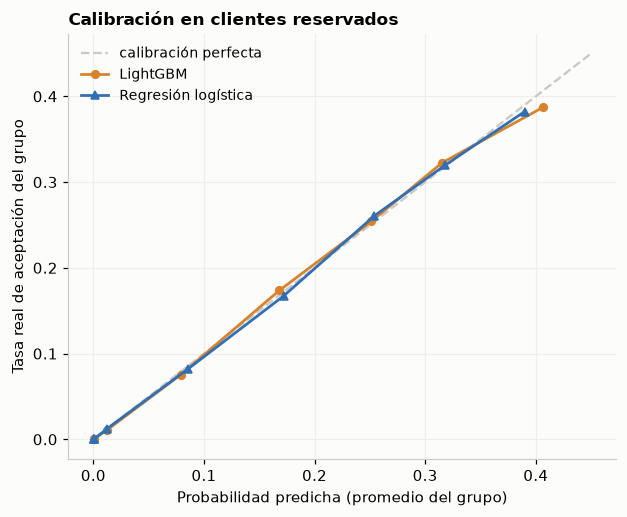

Mayor diferencia entre predicha y real en un decil: {'LightGBM': 0.0194, 'regresión': 0.0077}


In [9]:
p_lgbm, p_logit = check["lightgbm"]["p_start"], check["regresion_logistica"]["p_start"]
cost_lgbm, cost_logit = per_client_cost(yr, p_lgbm), per_client_cost(yr, p_logit)
gap = cost_logit - cost_lgbm                        # positivo = LightGBM es mejor
gap_low, gap_high = bootstrap_interval(gap, reserved["id"].to_numpy())

head_to_head = pd.DataFrame({
    "LightGBM": technical_metrics(yr, p_lgbm), "Regresión logística": technical_metrics(yr, p_logit),
}).loc[["cost", "pr_auc", "roc_auc", "recall_top", "precision_1", "recall_1", "contact_rate", "log_loss", "brier"]]
head_to_head.index = ["costo por cliente", "PR-AUC", "ROC-AUC", "recall en el 20 % mejor", "precisión (compradores)", "recall (compradores)", "% contactados", "log loss", "Brier"]
display(head_to_head.style.format("{:.4f}"))
print(f"Regresión menos LightGBM: {gap.mean():+.4f} por cliente, intervalo 95 % [{gap_low:+.4f}, {gap_high:+.4f}] "
      f"(≈ {gap.mean() * 100_000:,.0f} unidades por 100.000 clientes).")

def decile_gap(proba):
    groups = pd.qcut(pd.Series(proba).rank(method="first"), 10, labels=False)
    table = pd.DataFrame({"predicha": proba, "real": yr}).groupby(groups.to_numpy()).mean()
    return table

fig, ax = plt.subplots(figsize=(5.8, 4.8))
ax.plot([0, 0.45], [0, 0.45], color=LIGHT, lw=1.5, ls="--", label="calibración perfecta")
for name, proba, color, style in [("LightGBM", p_lgbm, ORANGE, "o-"), ("Regresión logística", p_logit, BLUE, "^-")]:
    t = decile_gap(proba)
    ax.plot(t["predicha"], t["real"], style, color=color, ms=5, lw=1.8, label=name)
ax.set_xlabel("Probabilidad predicha (promedio del grupo)")
ax.set_ylabel("Tasa real de aceptación del grupo")
ax.set_title("Calibración en clientes reservados")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()
print("Mayor diferencia entre predicha y real en un decil:", {n: round(float((decile_gap(p)["predicha"] - decile_gap(p)["real"]).abs().max()), 4) for n, p in [("LightGBM", p_lgbm), ("regresión", p_logit)]})

**Lectura:**
- **La regresión cuesta +0,0025 por cliente más que LightGBM, pero el intervalo [-0,0006, +0,0052] cruza el cero:** en los 76.000 clientes reservados **no se puede afirmar** que LightGBM sea mejor. En el torneo (5 pliegues) la ventaja era consistente (5 de 5 pliegues, +1,87 veces el ruido); aquí, **con una sola partición y un intervalo exigente, queda en el borde**. Es lo esperable de una diferencia real pero pequeña: **≈ 250 unidades por 100.000 clientes, menos del 1 % del costo total**.
- **LightGBM sí ordena mejor:** PR-AUC 0,369 frente a 0,354 y ROC-AUC más alto. La diferencia de ranking es clara; la de **costo** es pequeña. Para quien necesite **priorizar listas o trabajar con capacidad limitada**, LightGBM aporta algo más.
- **Ambos están bien calibrados en los reservados:** la mayor diferencia entre probabilidad predicha y real es de 0,019 en LightGBM y 0,008 en la regresión. **La probabilidad se puede usar tal cual** para fijar el umbral. LightGBM tiende a **ser algo optimista** en el grupo de mayor probabilidad (dice 40,7 % y el real es 38,8 %), un detalle a vigilar en la etapa 7.
- **La decisión entre los dos no es técnica sino de negocio:** si el negocio **exige explicar cada llamada**, la regresión cuesta poco y se puede defender con una fórmula (siguiente sección). Si no, LightGBM ordena algo mejor.

### 8.1 Lo que la regresión le dice al negocio

La regresión se explica con **razones de odds**: cuántas veces cambia la posibilidad de compra al pasar una variable de 0 a 1 (con las demás fijas). Es la **ventaja de explicabilidad** que se paga con ≈ 250 unidades por campaña.

In [10]:
pipe_logit = build_tuned_pipeline("regresion_logistica", START_PARAMS["regresion_logistica"]).fit(Xs, ys)
names = pipe_logit.named_steps["features"].get_feature_names_out()
coef = pipe_logit.named_steps["model"].coef_[0]
odds = pd.DataFrame({"variable": names, "coeficiente": coef, "razón de odds": np.exp(coef)}).set_index("variable")

key = odds.loc[["Previously_Insured", "Vehicle_Damage", "Premium_is_minimum"]].copy()
key.index = ["Ya tiene seguro de vehículo (1) frente a no (0)", "Vehículo con daño (1) frente a sin daño (0)", "Prima igual al mínimo (1) frente a otra (0)"]
display(key.style.format({"coeficiente": "{:+.3f}", "razón de odds": "{:.3f}"}))

channels = odds[odds.index.str.startswith("Policy_Sales_Channel")].sort_values("coeficiente")
print("Canales que más restan (razón de odds menor que 1):")
display(channels.head(4).style.format({"coeficiente": "{:+.3f}", "razón de odds": "{:.3f}"}))
print("Canales que más suman (razón de odds mayor que 1):")
display(channels.tail(3).sort_values("coeficiente", ascending=False).style.format({"coeficiente": "{:+.3f}", "razón de odds": "{:.3f}"}))

,coeficiente,razón de odds
Ya tiene seguro de vehículo (1) frente a no (0),-4.039,0.018
Vehículo con daño (1) frente a sin daño (0),+1.914,6.782
Prima igual al mínimo (1) frente a otra (0),-0.110,0.896


Canales que más restan (razón de odds menor que 1):


,coeficiente,razón de odds
variable,,
Policy_Sales_Channel_160,-1.139,0.320
Policy_Sales_Channel_151,-0.855,0.425
Policy_Sales_Channel_152,-0.666,0.514
Policy_Sales_Channel_1,-0.414,0.661


Canales que más suman (razón de odds mayor que 1):


,coeficiente,razón de odds
variable,,
Policy_Sales_Channel_155,+0.619,1.856
Policy_Sales_Channel_3,+0.588,1.801
Policy_Sales_Channel_163,+0.449,1.566


**Lectura para el equipo comercial:**
- **Quien ya tiene seguro de vehículo tiene un 98 % menos de posibilidades de comprar** (razón de odds 0,018): es **el** factor decisivo. Coincide con el EDA (0,1 % de aceptación).
- **Quien tuvo un daño tiene casi 7 veces más posibilidades** (razón de odds 6,8), con lo demás fijo.
- **Los canales 160, 151 y 152 restan** (razones de odds de 0,32, 0,43 y 0,51), en línea con su baja conversión en el EDA; hay canales que suman (155 y 3).
- **Esta es la explicación que ofrecería la regresión a un cliente o a un regulador:** "se le llamó porque no tiene seguro de vehículo y tuvo un daño reciente". Con LightGBM la explicación sería **aproximada** (importancias y valores SHAP, en la etapa 7).

## 9. Comprobar el seguimiento: ¿está todo registrado?

Se consulta MLflow para verificar que **cada ensayo es una ejecución** con sus parámetros, su métrica y sus etiquetas, y que se pueden **ordenar por la métrica principal**.

In [11]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string=f"tags.ejecucion = '{EXEC_ID}'")
counts = runs.groupby("tags.finalista").size()
print(f"Ejecuciones registradas en esta corrida: {len(runs)} (presupuesto: {N_TRIALS} por finalista = {N_TRIALS * len(FINALISTS)}).")
display(counts.rename("ejecuciones").to_frame())
assert (counts == N_TRIALS).all() and len(runs) == N_TRIALS * len(FINALISTS), "faltan ensayos en MLflow"

best_runs = (runs.sort_values("metrics.cost").groupby("tags.finalista").head(3)
             [["tags.finalista", "tags.mlflow.runName", "metrics.cost", "metrics.pr_auc", "tags.es_partida"]]
             .rename(columns={"tags.finalista": "finalista", "tags.mlflow.runName": "ejecución", "metrics.cost": "costo", "metrics.pr_auc": "PR-AUC", "tags.es_partida": "¿es la partida?"}))
print("Las 3 mejores ejecuciones de cada finalista, ordenadas por costo:")
display(best_runs.sort_values(["finalista", "costo"]).set_index("finalista").style.format({"costo": "{:.4f}", "PR-AUC": "{:.4f}"}))

Ejecuciones registradas en esta corrida: 40 (presupuesto: 20 por finalista = 40).


,ejecuciones
tags.finalista,
lightgbm,20
regresion_logistica,20


Las 3 mejores ejecuciones de cada finalista, ordenadas por costo:


,ejecución,costo,PR-AUC,¿es la partida?
finalista,,,,
lightgbm,lightgbm-ensayo-13,0.3259,0.3702,False
lightgbm,lightgbm-ensayo-06,0.3260,0.3691,False
lightgbm,lightgbm-ensayo-19,0.3263,0.3673,False
regresion_logistica,regresion_logistica-ensayo-00,0.3277,0.3575,True
regresion_logistica,regresion_logistica-ensayo-06,0.3277,0.3593,False
regresion_logistica,regresion_logistica-ensayo-08,0.3279,0.3580,False


**Lectura:** los **40 ensayos están registrados** (20 por finalista), cada uno con sus parámetros, su costo, su PR-AUC, su log loss y etiquetas (`finalista`, `es_partida`, `ejecucion`). Se pueden ordenar por costo y filtrar. **Para el finalista de regresión, la mejor ejecución es la de partida**, lo que deja una prueba auditable de que la búsqueda no encontró nada mejor.

## 10. Guardar la decisión

In [12]:
decision = {
    "etapa": "06_optimizacion",
    "presupuesto_por_finalista": N_TRIALS,
    "datos": {"busqueda": len(search), "reservados": len(reserved), "pliegues_de_busqueda": len(search_folds),
              "nota": "un cliente por fila (id unico): reservar por fila es reservar por cliente"},
    "regla_de_decision": "usar los parametros optimizados solo si todo el intervalo del 95 % de (optimizado - partida) esta por debajo de cero en los clientes reservados",
    "umbral": {"regla": "1 / (R + 1)", "R": 5, "valor": round(theory, 4), "minimo_empirico": empirical, "banda_a_menos_de_0.001": [float(band.min()), float(band.max())],
               "mantener_el_teorico": bool(not (high_t < 0)), "porcentaje_de_clientes_llamados": round(share_threshold, 3)},
    "finalistas": {
        f: {"parametros_a_usar": (c["best_params"] if c["decision"] == "optimizados" else START_PARAMS[f]),
            "decision": c["decision"], "parametros_de_partida": START_PARAMS[f], "mejor_encontrado": c["best_params"],
            "diferencia_en_reservados": round(float(c["difference"].mean()), 5), "intervalo_95": [round(c["low"], 5), round(c["high"], 5)]}
        for f, c in check.items()},
    "comparacion_de_finalistas": {"regresion_menos_lightgbm": round(float(gap.mean()), 5), "intervalo_95": [round(gap_low, 5), round(gap_high, 5)]},
    "tracking": {"donde": tracking_where, "experimento": EXPERIMENT, "ejecucion": EXEC_ID, "ensayos_registrados": int(len(runs))},
}
output = ROOT / "reports" / "06_best_params.json"
output.write_text(json.dumps(decision, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Guardado:", output.name)
print({f: decision["finalistas"][f]["decision"] for f in FINALISTS})

Guardado: 06_best_params.json
{'lightgbm': 'de partida', 'regresion_logistica': 'de partida'}


## 11. Qué sigue y qué necesitamos del negocio

### 11.1 Qué modelo pasa a la validación final (etapa 7)

**Propuesta [DECIDE EL GRUPO]:**

| Modelo | Papel | Por qué |
|---|---|---|
| **LightGBM** (parámetros de partida) | **Principal** | Menor costo y mejor ranking; calibrado; rápido de reentrenar |
| **Regresión logística** (parámetros de partida) | **Alternativa explicable** | Cuesta ≈ 250 unidades por 100.000 clientes más (diferencia no demostrable); se explica con una fórmula |

**Regla para la prueba cerrada:** se abre **una sola vez**, y la decisión de **cuál es el modelo desplegado** se toma **antes de abrirla**. Propuesta: si el negocio **exige explicar cada llamada**, el modelo desplegado es la regresión; si no, LightGBM. **La prueba se usa para confirmar la cifra del modelo elegido**, no para elegir entre ellos.

### 11.2 Decisiones de negocio antes de la etapa 7 [DECIDE EL GRUPO]

| # | Decisión | Propuesta | Por qué importa |
|---|---|---|---|
| 1 | **¿Se exige explicar cada llamada?** | Confirmarlo con Negocio y Legal | Decide el modelo desplegado (sección anterior) |
| 2 | **Operar por umbral o por capacidad fija** | **Umbral (16,7 %)**, dimensionando al equipo para ≈ 35 % de la base | Con capacidad fija del 20 % se pierde el 42 % de los compradores (≈ 6.000 unidades por 100.000 clientes) |
| 3 | **Confirmar R** | Estimar margen por venta ÷ costo de llamada | El umbral se mueve poco con errores pequeños de R (zona plana de 15 % a 17,5 %), así que **no bloquea** la etapa 7 |
| 4 | **Piso de contacto para 20-25 y 66+** | Definir antes de la auditoría de equidad | El modelo casi no los llama (vista previa de la etapa 5); la etapa 7 lo mide con la prueba cerrada |
| 5 | **Cuándo volver a optimizar** | **No antes de tener datos nuevos** (historial de contactos, vencimiento del seguro actual) | Optimizar dio cero mejora demostrable: el techo está en los datos, no en los parámetros |

### 11.3 Qué aprendimos (para el informe)

1. **Los parámetros del torneo ya eran buenos.** Optimizar no mejoró nada de forma demostrable, y la búsqueda estuvo a punto de hacernos creer lo contrario.
2. **El sesgo optimista es real:** la mejora aparente de LightGBM (0,0011) **desapareció** en clientes que la búsqueda no vio.
3. **El umbral teórico es robusto:** la zona plana de 15 % a 17,5 % protege al negocio de errores pequeños en R.
4. **La diferencia entre los finalistas no es demostrable** con una partición honesta: la elección es de **explicabilidad**, no de precisión.

## 12. Pruebas automáticas

In [13]:
import subprocess

res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no", "tests/test_tuning.py", "tests/test_models.py", "tests/test_tournament.py"],
                     cwd=ROOT, capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1])
assert res.returncode == 0, res.stdout[-2000:]

39 passed in 12.78s


## Entregable de esta etapa

- [x] **Un ensayo = una ejecución registrada** en MLflow, con parámetros, métrica y etiquetas (40 en total).
- [x] El **presupuesto** (20 ensayos por finalista) está escrito y se respetó; el ensayo 0 es la partida.
- [x] Hay **clientes reservados** (25 %, 76.222) que la búsqueda nunca vio.
- [x] La **comprobación** (intervalo del 95 % remuestreando clientes) está hecha y **la regla estaba escrita antes**.
- [x] `reports/06_best_params.json` y `reports/06_optimizacion.md` completados.
- [ ] El grupo confirma la regla de decisión y las decisiones de la sección 11.2.
- [ ] Revisión del código con `material-del-curso/kit/checklist-revision-ia.md`.

**Siguiente:** `07_validacion_interpretacion.ipynb`: se abre la prueba cerrada **una sola vez**, se audita la equidad y se interpreta el modelo.